# Методы обработки и распознавания изображений 

## Практическое занятие 1: Введение в PyTorch

Сегодня мы познакомимся с библиотекой **PyTorch**. Она очень похожа на **NumPy**, с одним важным отличием — **PyTorch** может считать градиенты за вас. Таким образом вам не надо будет писать обратный проход в нейросетях.

In [65]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import torchvision
from torch import nn
from tqdm import tqdm

### 1. Сравнение **NumPy** и **PyTorch**

Мы можем создавать матрицы, перемножать их, складывать, транспонировать и в целом совершать любые матричные операции

In [2]:
# случайная матрица
a = np.random.rand(5, 3)
a

array([[0.85866201, 0.25972567, 0.88534117],
       [0.55273035, 0.88231416, 0.79936465],
       [0.0188517 , 0.4063517 , 0.57418398],
       [0.9242336 , 0.14796966, 0.0369401 ],
       [0.46450528, 0.02137488, 0.17148836]])

In [3]:
# размеры массива
a.shape

(5, 3)

In [4]:
# сложение
a + 5

array([[5.85866201, 5.25972567, 5.88534117],
       [5.55273035, 5.88231416, 5.79936465],
       [5.0188517 , 5.4063517 , 5.57418398],
       [5.9242336 , 5.14796966, 5.0369401 ],
       [5.46450528, 5.02137488, 5.17148836]])

In [5]:
# матричное умножение
a @ a.T

array([[1.58858685, 1.41147862, 0.63007592, 0.86474039, 0.55623035],
       [1.41147862, 1.72297296, 0.82793214, 0.6709363 , 0.41268726],
       [0.63007592, 0.82793214, 0.49516433, 0.09876151, 0.1159083 ],
       [0.86474039, 0.6709363 , 0.09876151, 0.87746734, 0.43880902],
       [0.55623035, 0.41268726, 0.1159083 , 0.43880902, 0.2456303 ]])

In [6]:
# среднее по колонкам
a.mean(axis=-1)

array([0.66790961, 0.74480305, 0.33312913, 0.36971445, 0.21912284])

In [7]:
# решейп
a.reshape(3, 5).shape

(3, 5)

#### Разминка

При помощи **NumPy** посчитайте сумму квадратов натуральных чисел от 1 до 10000.

In [8]:
# YOUR CODE
numbers = np.arange(1, 10001)
result = np.sum(numbers ** 2)

print(result)

333383335000


Аналогичные операции в **PyTorch** очень похожи, но иногда имеют немного другой синтаксис

In [9]:
# случайный тензор
x = torch.rand(5, 3)
x

tensor([[0.1201, 0.6396, 0.6785],
        [0.9409, 0.7657, 0.4878],
        [0.7389, 0.1004, 0.5318],
        [0.1920, 0.3319, 0.1073],
        [0.4701, 0.1453, 0.3751]])

In [10]:
# размеры тензора
x.shape

torch.Size([5, 3])

In [11]:
# тоже размеры тензора
x.size()

torch.Size([5, 3])

In [12]:
# сложение
x + 5

tensor([[5.1201, 5.6396, 5.6785],
        [5.9409, 5.7657, 5.4878],
        [5.7389, 5.1004, 5.5318],
        [5.1920, 5.3319, 5.1073],
        [5.4701, 5.1453, 5.3751]])

In [13]:
# матричное умножение
# читайте документацию по различным вариантам: @, torch.mm, torch.matmul, torch.bmm
torch.matmul(x, x.transpose(1, 0))

tensor([[0.8839, 0.9337, 0.5138, 0.3082, 0.4039],
        [0.9337, 1.7095, 1.0315, 0.4871, 0.7365],
        [0.5138, 1.0315, 0.8389, 0.2322, 0.5614],
        [0.3082, 0.4871, 0.2322, 0.1585, 0.1787],
        [0.4039, 0.7365, 0.5614, 0.1787, 0.3828]])

In [14]:
# очередное матричное умножение
x.mm(x.t())

tensor([[0.8839, 0.9337, 0.5138, 0.3082, 0.4039],
        [0.9337, 1.7095, 1.0315, 0.4871, 0.7365],
        [0.5138, 1.0315, 0.8389, 0.2322, 0.5614],
        [0.3082, 0.4871, 0.2322, 0.1585, 0.1787],
        [0.4039, 0.7365, 0.5614, 0.1787, 0.3828]])

In [15]:
# поэлементное умножение
x * x

tensor([[0.0144, 0.4091, 0.4604],
        [0.8853, 0.5863, 0.2380],
        [0.5460, 0.0101, 0.2828],
        [0.0369, 0.1102, 0.0115],
        [0.2210, 0.0211, 0.1407]])

In [16]:
# среднее по колонкам
x.mean(dim=-1)

tensor([0.4794, 0.7315, 0.4570, 0.2104, 0.3302])

In [17]:
# решейп
x.view([3, 5]).shape

torch.Size([3, 5])

In [18]:
# или так
x.reshape([3, 5]).shape

torch.Size([3, 5])

In [19]:
# будьте внимательны и не используйте view для транспонирования осей!
x.view_as(x.t()) == x.t()

tensor([[ True, False, False, False, False],
        [False, False,  True, False, False],
        [False, False, False, False,  True]])

Небольшой пример того, как меняются операции:

* `x.reshape([1,2,8]) -> x.view(1,2,8)`

* `x.sum(axis=-1) -> x.sum(dim=-1)`

* `x.astype("int64") -> x.type(torch.LongTensor)`

Для помощи вам есть [таблица](https://github.com/torch/torch7/wiki/Torch-for-Numpy-users), которая поможет вам найти аналог **NumPy** операции в **PyTorch**


#### Разминка на pytorch

При помощи pytorch посчитайте сумму квадратов натуральных чисел от 1 до 10000.

In [20]:
arr = torch.arange(1, 10001)
s = torch.sum(arr ** 2)

print(s)

tensor(333383335000)


### 2. Создаем тензоры в **PyTorch** и изучаем больше базовых операций

In [21]:
# пустой тензор
x = torch.empty(5, 3)
x

tensor([[2.5448e-29, 1.2808e-42, 0.0000e+00],
        [0.0000e+00, 0.0000e+00, 0.0000e+00],
        [0.0000e+00, 0.0000e+00, 0.0000e+00],
        [0.0000e+00, 0.0000e+00, 0.0000e+00],
        [0.0000e+00, 0.0000e+00, 0.0000e+00]])

In [22]:
# случайный тензор ~ Uniform[0, 1)
x = torch.rand(5, 3)
x

tensor([[0.5050, 0.5400, 0.4324],
        [0.1683, 0.6301, 0.3322],
        [0.1873, 0.3083, 0.1537],
        [0.6224, 0.0524, 0.5952],
        [0.3293, 0.5830, 0.2502]])

In [23]:
# тензор с нулями и указанием типов чисел
x = torch.zeros(5, 3, dtype=torch.float32)
x

tensor([[0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.]])

In [24]:
# конструируем тензор из питоновского листа
x = torch.tensor([5.5, 3])
x

tensor([5.5000, 3.0000])

In [25]:
# используем уже созданный тензор для создания тензора из единичек
x1 = x.new_ones(5, 3, dtype=torch.double)
x1

tensor([[1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.]], dtype=torch.float64)

In [26]:
# создаем случайный тензор с размерами другого тензора
x = torch.randn_like(x1, dtype=torch.float)
x

tensor([[ 0.9051, -1.0868, -1.7209],
        [-1.2650,  0.0235, -0.4407],
        [-1.0409, -0.8516, -0.7420],
        [-0.1193,  1.4408,  0.3020],
        [-0.1488, -0.9003,  1.1005]])

In [27]:
x = torch.rand(5, 3)
y = torch.rand(5, 3)

In [28]:
x

tensor([[0.1139, 0.5595, 0.1588],
        [0.2296, 0.0429, 0.0271],
        [0.5366, 0.9452, 0.6028],
        [0.1373, 0.1500, 0.8515],
        [0.3023, 0.1821, 0.0663]])

In [29]:
y

tensor([[0.8178, 0.2895, 0.0538],
        [0.7907, 0.0498, 0.9183],
        [0.7012, 0.4723, 0.1522],
        [0.6741, 0.3327, 0.6661],
        [0.2738, 0.2325, 0.7389]])

In [30]:
# сложение
x + y

tensor([[0.9317, 0.8491, 0.2126],
        [1.0203, 0.0927, 0.9454],
        [1.2379, 1.4175, 0.7550],
        [0.8114, 0.4827, 1.5176],
        [0.5761, 0.4146, 0.8052]])

In [31]:
# очередное сложение
z = torch.add(x, y)
z

tensor([[0.9317, 0.8491, 0.2126],
        [1.0203, 0.0927, 0.9454],
        [1.2379, 1.4175, 0.7550],
        [0.8114, 0.4827, 1.5176],
        [0.5761, 0.4146, 0.8052]])

In [32]:
# наконец, ещё одно сложение!
torch.add(x, y, out=x)
x

tensor([[0.9317, 0.8491, 0.2126],
        [1.0203, 0.0927, 0.9454],
        [1.2379, 1.4175, 0.7550],
        [0.8114, 0.4827, 1.5176],
        [0.5761, 0.4146, 0.8052]])

In [33]:
# добавили измерение в начало
x.unsqueeze(0).size()

torch.Size([1, 5, 3])

In [34]:
# убрали одно единичное измерение
x.unsqueeze(0).unsqueeze(1).squeeze(0).size()

torch.Size([1, 5, 3])

In [35]:
# убрали все единичные измерения
x.unsqueeze(0).unsqueeze(1).squeeze().size()

torch.Size([5, 3])

In [36]:
# операции без _ не меняют тензор, а создают копию
x.unsqueeze(0)
x.size()

torch.Size([5, 3])

In [37]:
# операции с _ меняют тензор
x.unsqueeze_(0)
x.size()

torch.Size([1, 5, 3])

Мы можем делать обычные срезы и переводить матрицы из **PyTorch** в **NumPy** и наоборот:

In [38]:
a = np.ones((3, 5))
x = torch.ones((3, 5))
np.allclose(x.numpy(), a)

True

In [39]:
np.allclose(x.numpy()[:, 1], a[:, 1])

True

In [40]:
torch.from_numpy(x.numpy())

tensor([[1., 1., 1., 1., 1.],
        [1., 1., 1., 1., 1.],
        [1., 1., 1., 1., 1.]])

### 3. Работаем с градиентами руками

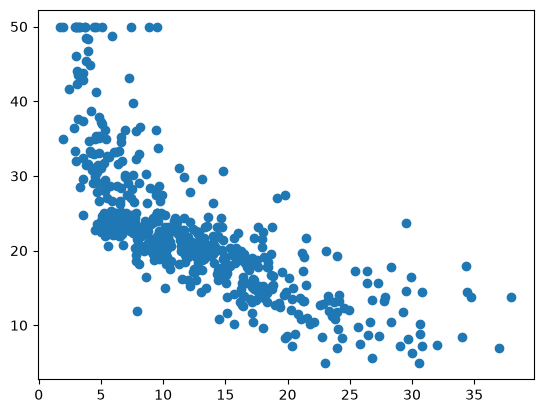

In [41]:
url = "https://lib.stat.cmu.edu/datasets/boston"
df = pd.read_csv(url, sep=r"\s+", skiprows=22, header=None)

x = np.hstack([df.values[::2, :], df.values[1::2, :2]])
y = df.values[1::2, 2]

plt.scatter(x[:, -1], y);

В **PyTorch** есть возможность при создании тензора указывать нужно ли считать по нему градиент или нет, с помощью параметра `requires_grad`. Когда `requires_grad=True` мы сообщаем фреймворку, о том, что мы хотим следить за всеми тензорами, которые получаются из созданного. Иными словами, у любого тензора, у которого указан данный параметр, будет доступ к цепочке операций и преобразований совершенными с ними. Если эти функции дифференцируемые, то у тензора появляется параметр `.grad`, в котором хранится значение градиента.

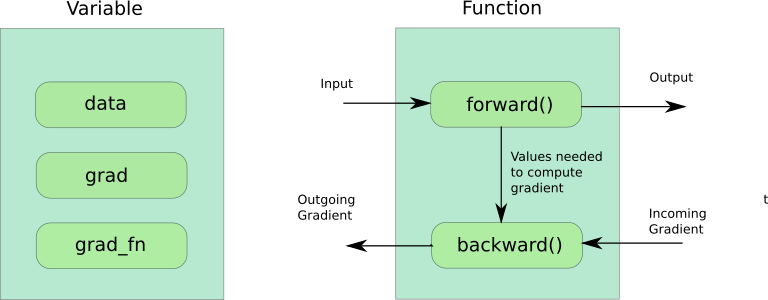

Если к результирующему тензору применить метод `.backward()`, то фреймворк посчитает по цепочке градиенты для всех тензоров, у которых `requires_grad=True`.

In [42]:
w = torch.rand(13, 1, requires_grad=True)
b = torch.rand(1, requires_grad=True)

x = torch.from_numpy(x).float()
y = torch.from_numpy(y).float()

y = y.reshape(-1, 1)

# только создали тензоры и в них нет градиентов
assert w.grad is None
assert b.grad is None

In [43]:
x.size(), y.size()

(torch.Size([506, 13]), torch.Size([506, 1]))

In [44]:
y_pred = x @ w + b
loss = torch.mean((y_pred - y) ** 2)
loss.backward()

In [45]:
# сделали операции и посчитали градиенты, появилось значение соответствующих полей
assert w.grad is not None
assert b.grad is not None

print(f"dL/dw = {w.grad}")
print(f"dL/db = {b.grad}")

dL/dw = tensor([[3.2846e+03],
        [7.4944e+03],
        [8.5783e+03],
        [4.7008e+01],
        [4.0234e+02],
        [4.3975e+03],
        [5.0461e+04],
        [2.5382e+03],
        [7.9038e+03],
        [3.1370e+05],
        [1.3176e+04],
        [2.5004e+05],
        [9.5531e+03]])
dL/db = tensor([705.7134])


Для доступа к значениям в тензоре используйте атрибут `.data`:

In [46]:
w.data, w.grad

(tensor([[0.1189],
         [0.8387],
         [0.2726],
         [0.7229],
         [0.7694],
         [0.0833],
         [0.2078],
         [0.4450],
         [0.0705],
         [0.4965],
         [0.1908],
         [0.3563],
         [0.8846]]),
 tensor([[3.2846e+03],
         [7.4944e+03],
         [8.5783e+03],
         [4.7008e+01],
         [4.0234e+02],
         [4.3975e+03],
         [5.0461e+04],
         [2.5382e+03],
         [7.9038e+03],
         [3.1370e+05],
         [1.3176e+04],
         [2.5004e+05],
         [9.5531e+03]]))

In [47]:
w

tensor([[0.1189],
        [0.8387],
        [0.2726],
        [0.7229],
        [0.7694],
        [0.0833],
        [0.2078],
        [0.4450],
        [0.0705],
        [0.4965],
        [0.1908],
        [0.3563],
        [0.8846]], requires_grad=True)

In [48]:
x = (x - x.mean(dim=0)) / x.std(dim=0)

In [49]:
x = torch.tensor(x[:, -1:], dtype=torch.float32)
y = torch.tensor(y, dtype=torch.float32).reshape(-1, 1)

x = (x - x.mean()) / x.std()

# Полином второй степени
x_poly = torch.cat([x, x ** 2], dim=1)

w = torch.zeros((2, 1), requires_grad=True)
b = torch.zeros(1, requires_grad=True)

C:\Users\Viking Ragnar\AppData\Local\Temp\ipykernel_16896\4172458229.py:1: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  x = torch.tensor(x[:, -1:], dtype=torch.float32)
C:\Users\Viking Ragnar\AppData\Local\Temp\ipykernel_16896\4172458229.py:2: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y = torch.tensor(y, dtype=torch.float32).reshape(-1, 1)


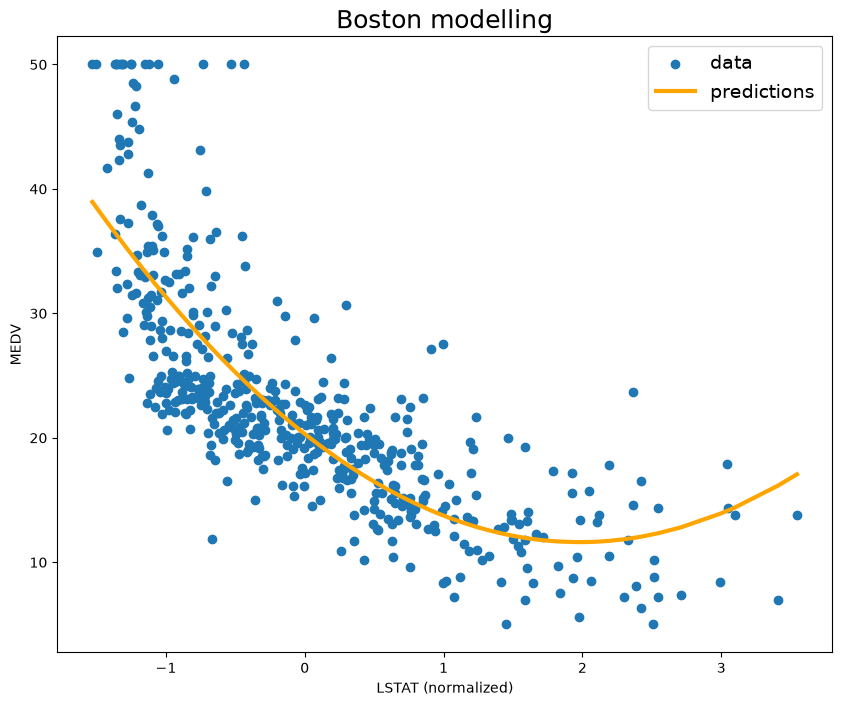

loss =  30.330524


In [50]:
from IPython.display import clear_output



for i in range(3000):
    y_pred = x_poly @ w + b
    # попробуйте сделать полиномиальную регрессию в данном предсказании и посчитать градиенты после
    loss = torch.mean((y_pred - y) ** 2)
    loss.backward()

    # делаем шаг градиентного спуска с lr = .05
    w.data -= 0.005 * w.grad
    b.data -= 0.005 * b.grad

    # обнуляем градиенты, чтобы на следующем шаге опять посчитать и не аккумулировать их
    w.grad.data.zero_()
    b.grad.data.zero_()

    # рисуем картинки
    if (i + 1) % 100 == 0:
        clear_output(True)
        plt.figure(figsize=(10, 8))

        plt.scatter(x.detach().numpy(), y.detach().numpy(), label="data")

        # Сортируем X, чтобы линия рисовалась по порядку
        idx = torch.argsort(x[:, 0])

        plt.plot(
            x[idx].detach().numpy(),
            y_pred[idx].detach().numpy(),
            color="orange",
            linewidth=3,
            label="predictions"
        )
        
        plt.title("Boston modelling", fontsize=18)
        plt.xlabel("LSTAT (normalized)")
        plt.ylabel("MEDV")
        plt.legend()
        plt.legend(fontsize=14)
        plt.show()
        


        print("loss = ", loss.data.numpy())
        if loss.data.numpy() < 0.1:
            print("Done!")
            break

### 4. Моя первая нейросеть

Для того, чтобы разобраться как обучать нейросети в **PyTorch**, нужно освоить три вещи:

1. Как формировать батчи и подавать их на вход сети
2. Как задать архитектуру сети
3. Как написать цикл обучения и отслеживать метрики

#### Как формировать батчи и подавать их на вход нейросети

Чтобы иметь возможность итерироваться по данным и применять к ним преобразования (например, аугментации, о которых вы узнаете позже), нужно создать свой класс унаследованный от `torch.utils.data.Dataset`.

У такого класса **должно быть** три метода:

* `__init__` — создаёт поля класса (например, путь к папке с файлами с тренировочными объектами)
* `__len__` — возвращает информацию о том, сколько объектов у нас в датасете
* `__getitem__` — по индексу возвращает семпл и таргет к нему


Давайте напишем такой сами, в качестве данных используя рандомные значения.

In [51]:
class RandomDataset(torch.utils.data.Dataset):
    """
    Our random dataset
    """

    def __init__(self, x, y):
        self.x = x
        self.y = y

    def __len__(self):
        return len(self.x)

    def __getitem__(self, idx):
        return {
            "sample": torch.tensor(self.x[idx, :], dtype=torch.float),
            "target": self.y[idx],
        }

In [52]:
x = np.random.rand(1000, 5)
y = np.random.rand(1000)

In [53]:
our_dataset = RandomDataset(x, y)

In [54]:
our_dataset.__getitem__(999)

{'sample': tensor([0.1054, 0.1433, 0.8002, 0.5444, 0.8623]),
 'target': np.float64(0.7978292495089737)}

Для того, чтобы из данных получать батчи в pytorch используется такая сущность как даталоадер, который принимает на вход класс унаследованный от `torch.utils.data.Dataset`. Посмотрим на пример:

In [55]:
dataloader = torch.utils.data.DataLoader(our_dataset, batch_size=4)

Работают с ним следующим образом:

In [56]:
batch = next(iter(dataloader))

print(f"Sample:\n{batch['sample']}")
print(f"Target:\n{batch['target']}")

Sample:
tensor([[0.2518, 0.9628, 0.2777, 0.0885, 0.3981],
        [0.3114, 0.5304, 0.6689, 0.1758, 0.6509],
        [0.9780, 0.2997, 0.8117, 0.3337, 0.2206],
        [0.1880, 0.1724, 0.2001, 0.3105, 0.6594]])
Target:
tensor([0.5068, 0.1597, 0.0935, 0.0954], dtype=torch.float64)


#### Как сделать нейросеть

Для того, чтобы в high-level **PyTorch** создавать нейросети, используется модуль `torch.nn`. Нейросеть должна быть унаследована от класса `nn.Module`. Пример как это может выглядеть:

```
class Model(nn.Module):
    def __init__(self):
        super(Model, self).__init__()
        self.conv1 = nn.Conv2d(1, 20, 5)
        self.conv2 = nn.Conv2d(20, 20, 5)

    def forward(self, x):
       x = F.relu(self.conv1(x))
       return F.relu(self.conv2(x))
```

Как мы видим на данном примере, у данного класса **должен быть** метод `forward`, который определяет прямой проход нейросети. Также из класса выше видно, что модуль `nn` содержит в себе реализацию большинства слоев, а модуль `nn.functional` -- функций активаций.

Есть еще один способ создать нейросеть и давайте его разберем на практике:

In [57]:
model = nn.Sequential()  # создаем пустую модель, в которую будем добавлять слои
model.add_module(
    "l1", nn.Linear(5, 30)
)  # добавили слой с 5-ю нейронами на вход и 3-мя на выход
model.add_module("l2", nn.ReLU())  # добавили функцию активации
model.add_module(
    "l3", nn.Linear(30, 1)
)  # добавили слой с 3-мя нейронами на вход и 5-ю на выход

# альтернативный способ
another_model = nn.Sequential(nn.Linear(5, 30), nn.ReLU(), nn.Linear(30, 1))

In [58]:
y_pred = model(batch["sample"])  # получили предсказания модели

#### Как написать цикл обучения и отслеживать метрики
 
Давайте теперь соберем теперь загрузку данных, создание модели и обучим на уже созданном для нас датасете MNIST

In [59]:
# используем готовый класс от торча для загрузки данных для тренировки
mnist_train = torchvision.datasets.MNIST(
    "./mnist/", train=True, download=True, transform=torchvision.transforms.ToTensor()
)
mnist_val = torchvision.datasets.MNIST(
    "./mnist/", train=False, download=True, transform=torchvision.transforms.ToTensor()
)

# так как это уже унаследованный от Dataset класс, его можно сразу обернуть в даталоадер
train_dataloader = torch.utils.data.DataLoader(
    mnist_train, batch_size=4, shuffle=True, num_workers=1
)

val_dataloader = torch.utils.data.DataLoader(
    mnist_val, batch_size=4, shuffle=False, num_workers=1
)

100%|██████████| 9.91M/9.91M [01:34<00:00, 105kB/s] 
100%|██████████| 28.9k/28.9k [00:00<00:00, 192kB/s]
100%|██████████| 1.65M/1.65M [00:12<00:00, 134kB/s] 
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.71MB/s]


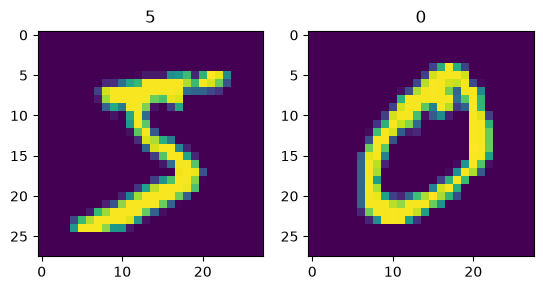

In [60]:
# посмотрим на то, с чем мы работаем
for i in [0, 1]:
    plt.subplot(1, 2, i + 1)
    plt.imshow(mnist_train[i][0].squeeze(0).numpy().reshape([28, 28]))
    plt.title(str(mnist_train[i][1]))
plt.show()

In [61]:
model = nn.Sequential(
    nn.Flatten(),  # превращаем картинку 28х28 в вектор размером 784
    nn.Linear(
        28 * 28, 128
    ),  # линейный слой, преобразующий вектор размера 784 в вектор размера 128
    nn.ReLU(),  # нелинейность
    nn.Linear(
        128, 10
    ),  # линейный слой, преобразующий вектор размера 128 в вектор размера 10
)

# создаем оптимизатор, который будет обновлять веса модели
optimizer = torch.optim.SGD(model.parameters(), lr=0.05)

Веса моделей хранятся в виде матриц и выглядят так:

In [62]:
[x for x in model.named_parameters()]

[('1.weight',
  Parameter containing:
  tensor([[ 4.7866e-05, -2.0567e-02,  9.3200e-03,  ..., -1.8992e-02,
            1.1997e-02, -3.1425e-03],
          [-2.9100e-02, -6.8670e-03,  3.1542e-02,  ...,  2.7152e-02,
            9.2791e-03,  3.9778e-03],
          [-2.2229e-02, -2.7037e-02, -2.3594e-02,  ...,  2.8262e-02,
           -3.3592e-02,  4.6933e-03],
          ...,
          [ 2.1386e-02, -1.9744e-02, -3.5696e-02,  ..., -2.2258e-02,
           -2.6030e-02, -7.7465e-03],
          [-1.6426e-02, -1.3293e-02, -3.2947e-02,  ...,  1.8788e-02,
            9.2762e-04, -9.6056e-03],
          [-7.4198e-03,  2.9357e-02, -1.5192e-02,  ...,  1.3412e-02,
           -1.3815e-02,  2.5953e-02]], requires_grad=True)),
 ('1.bias',
  Parameter containing:
  tensor([-0.0043, -0.0103,  0.0311, -0.0316, -0.0027, -0.0009,  0.0333,  0.0307,
          -0.0068, -0.0107,  0.0348,  0.0031, -0.0156, -0.0344, -0.0165,  0.0019,
          -0.0316,  0.0193, -0.0082, -0.0023, -0.0097,  0.0091, -0.0109,  0.0174,


In [69]:
# всего у нас будет 5 эпох (5 раз подряд пройдемся по всем батчам из трейна)
for epoch in range(10):
    for x_train, y_train in tqdm(train_dataloader):  # берем батч из трейн лоадера
        y_pred = model(x_train)  # делаем предсказания
        loss = F.cross_entropy(y_pred, y_train)  # считаем лосс
        loss.backward()  # считаем градиенты обратным проходом
        optimizer.step()  # обновляем параметры сети
        optimizer.zero_grad()  # обнуляем посчитанные градиенты параметров

    if epoch % 2 == 0:
        val_loss = []  # сюда будем складывать **средний по бачу** лосс
        val_accuracy = []
        with torch.no_grad():  # на валидации запрещаем фреймворку считать градиенты по параметрам
            for x_val, y_val in tqdm(
                val_dataloader
            ):  # берем батч из валидационного лоадера
                y_pred = model(x_val)  # делаем предсказания
                loss = F.cross_entropy(y_pred, y_val)  # считаем лосс
                val_loss.append(loss.numpy())  # добавляем в массив
                val_accuracy.extend(
                    (torch.argmax(y_pred, dim=-1) == y_val).numpy().tolist()
                )

        # печатаем метрики
        print(
            f"Epoch: {epoch}, loss: {np.mean(val_loss)}, accuracy: {np.mean(val_accuracy)}"
        )

100%|██████████| 2500/2500 [00:04<00:00, 520.20it/s] 


Epoch: 0, loss: 0.08713135123252869, accuracy: 0.9805


100%|██████████| 2500/2500 [00:04<00:00, 517.60it/s] 


Epoch: 2, loss: 0.08643897622823715, accuracy: 0.9811


100%|██████████| 2500/2500 [00:04<00:00, 513.70it/s] 


...

100%|██████████| 2500/2500 [00:04<00:00, 518.75it/s] 


Epoch: 6, loss: 0.08670765906572342, accuracy: 0.9826


100%|██████████| 2500/2500 [00:04<00:00, 510.29it/s] 


Epoch: 8, loss: 0.08715895563364029, accuracy: 0.9827


100%|██████████| 15000/15000 [00:14<00:00, 1046.62it/s]


ДЗ: Вам необходимо переписать алгоритм обучения нейронной сети, с целью повышения значения accuracy. Можно пробовать оптимизировать код, саму нейронку или параметры обучения.